<a href="https://colab.research.google.com/github/malak-dotcom/DSP_project/blob/main/life%20expectancy%20data%20processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression

In [5]:
df=pd.read_csv('Life Expectancy Data.csv')
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [6]:
df.shape

(2938, 22)

In [7]:
df.isnull().sum()

,0
Country,0
Year,0
Status,0
Life expectancy,10
Adult Mortality,10
infant deaths,0
Alcohol,194
percentage expenditure,0
Hepatitis B,553
Measles,0


In [8]:
import numpy as np
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median().iloc[0])
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
df[categorical_cols] = df[categorical_cols].fillna(df[categorical_cols].mode().iloc[0])

In [10]:
df = df.drop_duplicates()
df.shape

(2938, 22)

In [9]:
#outlier
numeric_df = df.select_dtypes(include=np.number) # Select only numeric columns
q1 = numeric_df.quantile(0.25)
q3 = numeric_df.quantile(0.75)
iqr = q3 - q1
upperlimit = q3 + 1.5 * iqr
lowerlimit = q1 - 1.5 * iqr
for col in numeric_df.columns:
    df[col] = np.where(df[col] < lowerlimit[col], lowerlimit[col], df[col])
    df[col] = np.where(df[col] > upperlimit[col], upperlimit[col], df[col])


In [11]:
#encoding
label_encoder = LabelEncoder()
df['Country'] = label_encoder.fit_transform(df['Country'])
df['Status'] = label_encoder.fit_transform(df['Status'])
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,0,2015.0,1,65.0,263.0,55.0,0.01,71.279624,65.0,900.625,...,49.5,8.16,65.0,0.1,584.259210,11452116.75,15.85,15.85,0.479,10.1
1,0,2014.0,1,59.9,271.0,55.0,0.01,73.523582,62.0,492.000,...,58.0,8.18,62.0,0.1,612.696514,327582.00,15.85,15.85,0.476,10.0
2,0,2013.0,1,59.9,268.0,55.0,0.01,73.219243,64.0,430.000,...,62.0,8.13,64.0,0.1,631.744976,11452116.75,15.85,15.85,0.470,9.9
3,0,2012.0,1,59.5,272.0,55.0,0.01,78.184215,67.0,900.625,...,67.0,8.52,67.0,0.1,669.959000,3696958.00,15.85,15.85,0.463,9.8
4,0,2011.0,1,59.2,275.0,55.0,0.01,7.097109,68.0,900.625,...,68.0,7.87,68.0,0.1,63.537231,2978599.00,15.85,15.85,0.454,9.5


In [12]:
#normalizatin
scaler = MinMaxScaler()
numeric_df = df.select_dtypes(include=np.number)
df[numeric_df.columns] = scaler.fit_transform(numeric_df)
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,0.0,1.000000,1.0,0.411,0.572052,1.0,0.0,0.064988,0.125000,1.000000,...,0.000000,0.574908,0.203947,0.0,0.052598,1.000000,1.0,1.0,0.353437,0.363636
1,0.0,0.933333,1.0,0.309,0.589520,1.0,0.0,0.067034,0.080882,0.546287,...,0.111842,0.576384,0.164474,0.0,0.055165,0.028602,1.0,1.0,0.350875,0.357955
2,0.0,0.866667,1.0,0.309,0.582969,1.0,0.0,0.066757,0.110294,0.477446,...,0.164474,0.572694,0.190789,0.0,0.056885,1.000000,1.0,1.0,0.345751,0.352273
3,0.0,0.800000,1.0,0.301,0.591703,1.0,0.0,0.071283,0.154412,1.000000,...,0.230263,0.601476,0.230263,0.0,0.060335,0.322817,1.0,1.0,0.339774,0.346591
4,0.0,0.733333,1.0,0.295,0.598253,1.0,0.0,0.006471,0.169118,1.000000,...,0.243421,0.553506,0.243421,0.0,0.005585,0.260089,1.0,1.0,0.332088,0.329545


In [13]:
#transformation
df[numeric_cols] = np.log1p(df[numeric_cols])

In [14]:
#split
X = df.drop('Status', axis=1)
y = df['Status']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
#impalance
df['Status'].value_counts(normalize=True)*100

,proportion
Status,
1.0,82.573179
0.0,17.426821


In [16]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
y_train = y_train.apply(lambda x: 1 if x > 0.0 else 0)
y_train = y_train.astype(int)
X_train,y_train = smote.fit_resample(X_train,y_train)

In [17]:
print(y_train.value_counts())

Status
1    1935
0    1935
Name: count, dtype: int64


In [18]:
#LogisticRegression
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [19]:

y_test_binary = y_test.apply(lambda x: 1 if x > 0.0 else 0)
y_test_binary = y_test_binary.astype(int)

print("Accuracy:", (accuracy_score(y_test_binary, y_pred))*100,'%')
print("Precision:", (precision_score(y_test_binary, y_pred))*100,'%')
print("Recall:", (recall_score(y_test_binary, y_pred))*100,'%')

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_binary, y_pred))

print("\nClassification Report:")
print(classification_report(y_test_binary, y_pred))

Accuracy: 90.47619047619048 %
Precision: 98.87640449438202 %
Recall: 89.61303462321793 %

Confusion Matrix:
[[ 92   5]
 [ 51 440]]

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.95      0.77        97
           1       0.99      0.90      0.94       491

    accuracy                           0.90       588
   macro avg       0.82      0.92      0.85       588
weighted avg       0.93      0.90      0.91       588



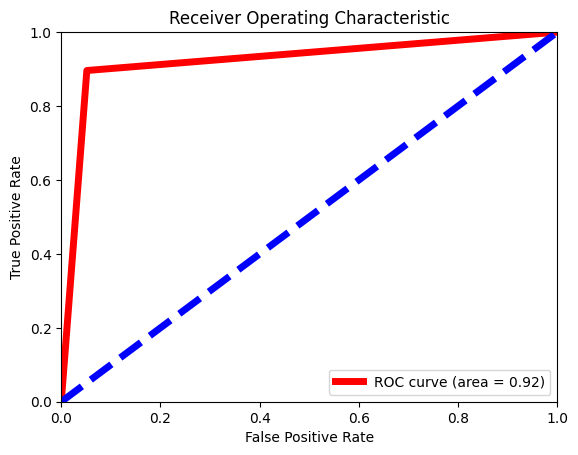

AUC: 92.22919772398009 %


In [20]:
#graph
from sklearn.metrics import roc_curve, auc
fpr, tpr, thresholds = roc_curve(y_test_binary, y_pred)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, color='red', lw=5, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='blue', lw=5, linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1])

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()
print("AUC:", (roc_auc)*100,'%')

In [21]:
import joblib

In [22]:
joblib.dump(model,"model.h5")

['model.h5']